<a href="https://colab.research.google.com/github/sandesh0shinde/House-Price_Prediction/blob/main/House_Price_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction using Machine Learning
Goals
- Explore a real-world dataset
- Train a lightweight Random Forest regression model
- Evaluate with MAE, RMSE, and R²
- Plot actual vs. predicted values

## Import Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

##Load the dataset

In [4]:
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target

In [5]:
print("Dataset shape:", X.shape)
display(X.head())

Dataset shape: (20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


##Explore the data
The target is measured in units of \$100,000.
For example, 2.0 means $200,000 in the dataset's target units.

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31


,"Median house value (units of $100,000)"
count,20640.00
mean,2.07
std,1.15
min,0.15
25%,1.20
50%,1.80
75%,2.65
max,5.00


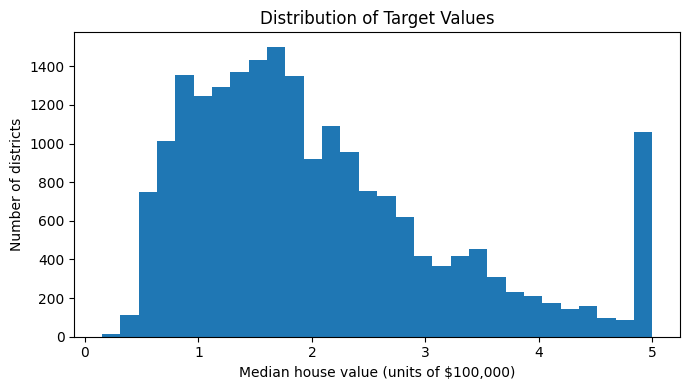

In [7]:
display(X.describe().round(2))
display(y.describe().to_frame(name="Median house value (units of $100,000)").round(2))

plt.figure(figsize=(7,4))
plt.hist(y, bins=30)
plt.title("Distribution of Target Values")
plt.xlabel("Median house value (units of $100,000)")
plt.ylabel("Number of districts")
plt.tight_layout()
plt.show()

##Split into training and test sets
We keep test data aside to evaluate the model on data it did not train on.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 16512
Test rows: 4128


In [9]:
X_train.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80


In [11]:
y_train.head()

,MedHouseVal
14196,1.030
8267,3.821
17445,1.726
14265,0.934
2271,0.965


##Train a lightweight model
This uses 80 trees to keep training reasonably lightweight. A GPU is not required.

In [13]:
model = RandomForestRegressor(
    n_estimators=80,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

RandomForestRegressor(min_samples_leaf=2, n_estimators=80, n_jobs=-1,
                      random_state=42)

##Evaluate the model

In [14]:
y_predict = model.predict(X_test)

mae = mean_absolute_error(y_test, y_predict)
rmse = mean_squared_error(y_test, y_predict) ** 0.5
r2 = r2_score(y_test, y_predict)

In [18]:
print(f"MAE : {mae:.3f} units of $100,000")
print(f"RMSE: {rmse:.3f} units of $100,000")
print(f"R²  : {r2:.3f}")

MAE : 0.328 units of $100,000
RMSE: 0.506 units of $100,000
R²  : 0.805


##Visualization of Actual vs. Predicted values
Points closer to the diagonal line indicate predictions closer to the true values.

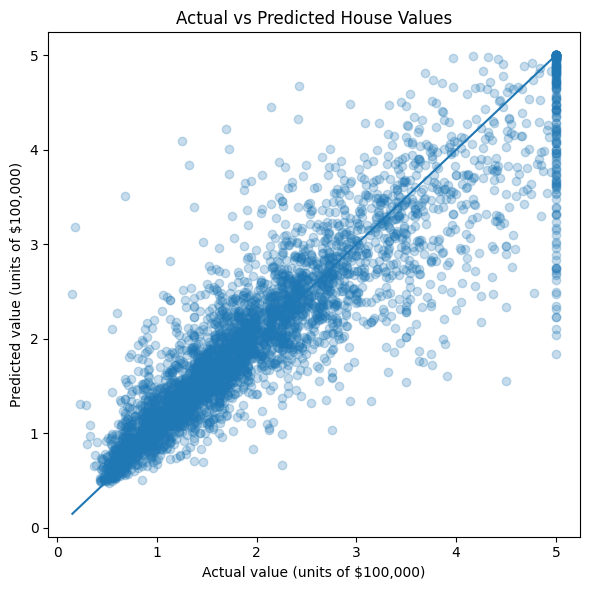

In [21]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_predict, alpha=0.25)

lower = min(float(y_test.min()), float(y_predict.min()))
upper = max(float(y_test.max()), float(y_predict.max()))

plt.plot([lower, upper], [lower, upper])
plt.xlabel("Actual value (units of $100,000)")
plt.ylabel("Predicted value (units of $100,000)")
plt.title("Actual vs Predicted House Values")

plt.tight_layout()
plt.show()

##Try a sample prediction

In [22]:
sample = X_test.iloc[[0]]
predicted_value = float(model.predict(sample)[0])
actual_value = float(y_test.iloc[0])

In [24]:
display(sample)
print(f"Predicted dataset median value: ${predicted_value * 100_000:,.0f}")
print(f"Actual dataset value:           ${actual_value * 100_000:,.0f}")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01


Predicted dataset median value: $51,122
Actual dataset value:           $47,700
